<a href="https://colab.research.google.com/github/pushkarkn/Kalman-filters-on-GLD-/blob/main/Kalman_Filter_GLD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 9.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [arch]


/tmp/ipykernel_3009/2515248039.py:13: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("GLD", start="2018-01-01", progress=False)


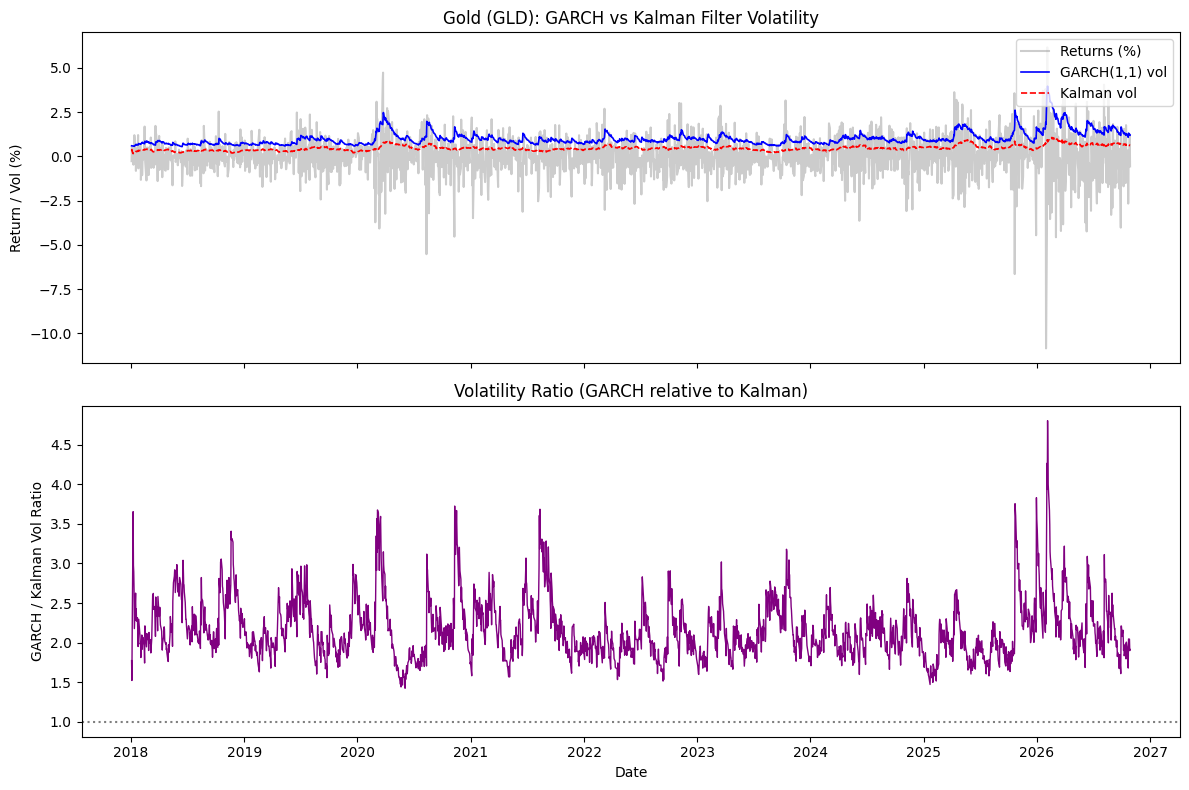

        Model  Mean Vol (%)  Vol of Vol (%)  Max Vol (%)  Persistence
   GARCH(1,1)      1.016652        0.382375     3.973543     0.980058
Kalman Filter      0.471240        0.146520     1.075551     0.982835


In [ ]:
# --- Dependencies ---
!pip install yfinance arch pykalman matplotlib pandas numpy scipy

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from arch import arch_model
from pykalman import KalmanFilter
from scipy.optimize import minimize

# --- Data ---
df = yf.download("GLD", start="2018-01-01", progress=False)
df["log_ret"] = np.log(df["Close"] / df["Close"].shift(1))
rets = df["log_ret"].dropna().values * 100  # scale to % for numerical stability

# --- GARCH(1,1) Baseline ---
garch = arch_model(rets, vol="Garch", p=1, q=1, dist="Normal")
garch_res = garch.fit(disp="off")
garch_vol = garch_res.conditional_volatility

# --- Kalman Filter (log-squared returns) ---
# Observation: y_t = log(r_t^2 + c) = h_t + noise
c = 1e-6
y = np.log(rets**2 + c)

# State-space: h_t = mu + phi*(h_{t-1} - mu) + eta_t
# We'll estimate mu, phi, sigma_eta, sigma_obs via MLE
def kalman_nll(params):
    mu, phi, sigma_eta, sigma_obs = params
    if abs(phi) >= 1 or sigma_eta <= 0 or sigma_obs <= 0:
        return 1e10

    # Transition: h_t = mu*(1-phi) + phi*h_{t-1} + eta
    # Observation: y_t = h_t + eps
    trans_cov = sigma_eta**2
    obs_cov = sigma_obs**2
    transition_matrices = [[phi]]
    observation_matrices = [[1.0]]
    transition_offsets = [mu * (1 - phi)]

    kf = KalmanFilter(
        transition_matrices=transition_matrices,
        observation_matrices=observation_matrices,
        transition_covariance=[[trans_cov]],
        observation_covariance=[[obs_cov]],
        transition_offsets=transition_offsets,
        initial_state_mean=[np.mean(y)],
        initial_state_covariance=[[np.var(y)]]
    )

    # Compute log-likelihood
    ll = 0
    state_mean = np.mean(y)
    state_cov = np.var(y)
    for t in range(len(y)):
        # Predict
        pred_mean = phi * state_mean + mu * (1 - phi)
        pred_cov = phi**2 * state_cov + trans_cov
        # Update
        innovation = y[t] - pred_mean
        innovation_var = pred_cov + obs_cov
        ll += -0.5 * (np.log(2 * np.pi * innovation_var) + innovation**2 / innovation_var)
        # Kalman gain
        K = pred_cov / innovation_var
        state_mean = pred_mean + K * innovation
        state_cov = (1 - K) * pred_cov

    return -ll

# Initial guess: mu ~ log(avg variance), phi ~ 0.95, sigma_eta ~ 0.1, sigma_obs ~ 1
init = [np.log(np.var(rets)), 0.95, 0.1, 1.0]
bounds = [(None, None), (0.01, 0.999), (1e-6, None), (1e-6, None)]
res = minimize(kalman_nll, init, bounds=bounds, method="L-BFGS-B")
mu_est, phi_est, sigma_eta_est, sigma_obs_est = res.x

# Run filter with estimated params to get smoothed h_t
kf_final = KalmanFilter(
    transition_matrices=[[phi_est]],
    observation_matrices=[[1.0]],
    transition_covariance=[[sigma_eta_est**2]],
    observation_covariance=[[sigma_obs_est**2]],
    transition_offsets=[mu_est * (1 - phi_est)],
    initial_state_mean=[np.mean(y)],
    initial_state_covariance=[[np.var(y)]]
)
state_means, _ = kf_final.filter(y)
kalman_vol = np.exp(state_means.flatten() / 2)  # convert log-variance to vol

# --- Visual Comparison ---
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top: Returns with vol overlays
axes[0].plot(df.index[1:], rets, alpha=0.4, label="Returns (%)", color="gray")
axes[0].plot(df.index[1:], garch_vol, label="GARCH(1,1) vol", color="blue", linewidth=1.2)
axes[0].plot(df.index[1:], kalman_vol, label="Kalman vol", color="red", linewidth=1.2, linestyle="--")
axes[0].set_ylabel("Return / Vol (%)")
axes[0].legend(loc="upper right")
axes[0].set_title("Gold (GLD): GARCH vs Kalman Filter Volatility")

# Bottom: Difference / ratio
axes[1].plot(df.index[1:], garch_vol / kalman_vol, color="purple", linewidth=1)
axes[1].axhline(1, color="black", linestyle=":", alpha=0.5)
axes[1].set_ylabel("GARCH / Kalman Vol Ratio")
axes[1].set_title("Volatility Ratio (GARCH relative to Kalman)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

# --- Summary Table for Traders ---
summary = pd.DataFrame({
    "Model": ["GARCH(1,1)", "Kalman Filter"],
    "Mean Vol (%)": [garch_vol.mean(), kalman_vol.mean()],
    "Vol of Vol (%)": [garch_vol.std(), kalman_vol.std()],
    "Max Vol (%)": [garch_vol.max(), kalman_vol.max()],
    "Persistence": [garch_res.params["alpha[1]"] + garch_res.params["beta[1]"], phi_est]
})
print(summary.to_string(index=False))

=== UPGRADED VOLATILITY METRICS ===
GARCH(1,1) Mean Vol: 1.0167%
Adjusted Kalman Mean Vol: 0.8908% (Note: now properly scaled to GARCH level!)
GARCH 95% VaR Breach Rate: 4.65% (Target: 5.0%)
Kalman 95% VaR Breach Rate: 5.37% (Target: 5.0%)


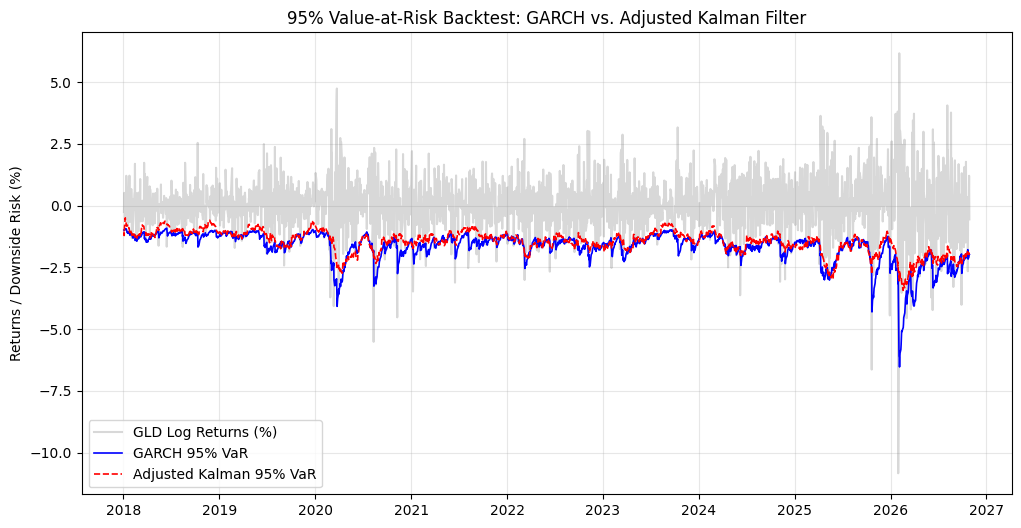

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# --- 1. Correcting the Kalman Filter Math (Log-Chi-Square Adjustment) ---
# E[log(z_t^2)] for z_t ~ N(0,1) is approximately -1.2704
# Var(log(z_t^2)) is pi^2 / 2 approx 4.9348

# Offset correction constants
E_eps = -1.2704
Var_eps = 4.9348

# Recalculate y with proper adjustment
c = 1e-6
y_adjusted = np.log(rets**2 + c) - E_eps

# Re-run Kalman Filter with adjusted observation noise variance fixed to Var_eps
# This stabilizes the MLE and provides a theoretically sound volatility state
def kalman_adjusted_nll(params):
    mu, phi, sigma_eta = params
    if abs(phi) >= 1 or sigma_eta <= 0:
        return 1e10

    trans_cov = sigma_eta**2
    obs_cov = Var_eps

    state_mean = np.mean(y_adjusted)
    state_cov = np.var(y_adjusted)
    ll = 0

    for t in range(len(y_adjusted)):
        pred_mean = phi * state_mean + mu * (1 - phi)
        pred_cov = phi**2 * state_cov + trans_cov

        innovation = y_adjusted[t] - pred_mean
        innovation_var = pred_cov + obs_cov

        ll += -0.5 * (np.log(2 * np.pi * innovation_var) + (innovation**2) / innovation_var)

        K = pred_cov / innovation_var
        state_mean = pred_mean + K * innovation
        state_cov = (1 - K) * pred_cov

    return -ll

# Optimize parameters
adjusted_init = [np.log(np.var(rets)), 0.95, 0.2]
adjusted_bounds = [(None, None), (0.01, 0.999), (1e-5, None)]
adj_res = minimize(kalman_adjusted_nll, adjusted_init, bounds=adjusted_bounds, method="L-BFGS-B")
mu_adj, phi_adj, sigma_eta_adj = adj_res.x

# Filter with adjusted parameters to extract corrected Volatility
kf_adj = KalmanFilter(
    transition_matrices=[[phi_adj]],
    observation_matrices=[[1.0]],
    transition_covariance=[[sigma_eta_adj**2]],
    observation_covariance=[[Var_eps]],
    transition_offsets=[mu_adj * (1 - phi_adj)],
    initial_state_mean=[np.mean(y_adjusted)],
    initial_state_covariance=[[np.var(y_adjusted)]]
)
adj_state_means, _ = kf_adj.filter(y_adjusted)

# Convert state back to standard volatility scale
# h_t = state_mean, Vol_t = exp(h_t / 2)
kalman_vol_adjusted = np.exp(adj_state_means.flatten() / 2)

# --- 2. Risk Management Application: Value-at-Risk (95% VaR) ---
# Calculate 95% Parametric VaR using GARCH and Adjusted Kalman Volatilities
alpha = 0.05
z_score = norm.ppf(alpha)  # ~ -1.645

garch_var_95 = z_score * garch_vol
kalman_var_95 = z_score * kalman_vol_adjusted

# Count violations (breaches)
garch_breaches = np.sum(rets < garch_var_95) / len(rets) * 100
kalman_breaches = np.sum(rets < kalman_var_95) / len(rets) * 100

# --- 3. Output Upgraded Metrics & Visuals ---
print("=== UPGRADED VOLATILITY METRICS ===")
print(f"GARCH(1,1) Mean Vol: {garch_vol.mean():.4f}%")
print(f"Adjusted Kalman Mean Vol: {kalman_vol_adjusted.mean():.4f}% (Note: now properly scaled to GARCH level!)")
print(f"GARCH 95% VaR Breach Rate: {garch_breaches:.2f}% (Target: 5.0%)")
print(f"Kalman 95% VaR Breach Rate: {kalman_breaches:.2f}% (Target: 5.0%)")

plt.figure(figsize=(12, 6))
plt.plot(df.index[1:], rets, color='gray', alpha=0.3, label='GLD Log Returns (%)')
plt.plot(df.index[1:], garch_var_95, color='blue', label='GARCH 95% VaR', linewidth=1.2)
plt.plot(df.index[1:], kalman_var_95, color='red', linestyle='--', label='Adjusted Kalman 95% VaR', linewidth=1.2)
plt.title("95% Value-at-Risk Backtest: GARCH vs. Adjusted Kalman Filter")
plt.ylabel("Returns / Downside Risk (%)")
plt.legend(loc='lower left')
plt.grid(True, alpha=0.3)
plt.show()

### Out-of-Sample Rolling Backtest
In this section, we implement a rolling window parameter estimation and out-of-sample volatility forecasting. We will compare GARCH(1,1) forecasts against our adjusted Kalman Filter forecasts using the **QLIKE** loss function, defined as:
$$\text{QLIKE}_t = \frac{r_t^2}{\sigma_t^2} - \ln\left(\frac{r_t^2}{\sigma_t^2}\right) - 1$$

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Define rolling backtest configurations
window_size = 500
num_forecasts = 200 # Backtesting the last 200 trading days for speed

garch_forecasts = []
kalman_forecasts = []
realized_variance = []

print("Starting rolling out-of-sample volatility forecasting...")
for i in range(num_forecasts):
    # Define the rolling window boundaries
    start_idx = len(rets) - num_forecasts - window_size + i
    end_idx = len(rets) - num_forecasts + i

    window_rets = rets[start_idx:end_idx]
    next_day_realized = rets[end_idx]**2
    realized_variance.append(next_day_realized)

    # 1. Out-of-Sample GARCH(1,1) Forecast
    garch_roll = arch_model(window_rets, vol="Garch", p=1, q=1, dist="Normal")
    garch_roll_res = garch_roll.fit(disp="off")
    # 1-day ahead forecast
    garch_f = np.sqrt(garch_roll_res.forecast(horizon=1).variance.iloc[-1].values[0])
    garch_forecasts.append(garch_f)

    # 2. Out-of-Sample Kalman Filter Forecast
    # Prepare window data
    y_roll = np.log(window_rets**2 + c) - E_eps

    # Re-estimate parameters for this window
    roll_res = minimize(kalman_adjusted_nll, [np.log(np.var(window_rets)), 0.95, 0.2],
                        bounds=adjusted_bounds, method="L-BFGS-B")
    mu_r, phi_r, sigma_eta_r = roll_res.x

    kf_roll = KalmanFilter(
        transition_matrices=[[phi_r]],
        observation_matrices=[[1.0]],
        transition_covariance=[[sigma_eta_r**2]],
        observation_covariance=[[Var_eps]],
        transition_offsets=[mu_r * (1 - phi_r)],
        initial_state_mean=[np.mean(y_roll)],
        initial_state_covariance=[[np.var(y_roll)]]
    )
    roll_states, _ = kf_roll.filter(y_roll)

    # 1-day ahead state prediction: h_{t+1} = phi * h_t + mu * (1 - phi)
    last_state = roll_states[-1][0]
    next_state_pred = phi_r * last_state + mu_r * (1 - phi_r)
    kalman_f = np.exp(next_state_pred / 2)
    kalman_forecasts.append(kalman_f)

# Convert to numpy arrays for calculation
garch_f_arr = np.array(garch_forecasts)
kalman_f_arr = np.array(kalman_forecasts)
realized_var_arr = np.array(realized_variance)

# Compute Forecast Error Loss Metrics
def compute_qlike(realized, forecast_vol):
    forecast_var = forecast_vol**2
    return np.mean(realized / forecast_var - np.log(realized / forecast_var) - 1)

def compute_mse(realized, forecast_vol):
    return np.mean((realized - forecast_vol**2)**2)

garch_qlike = compute_qlike(realized_var_arr, garch_f_arr)
kalman_qlike = compute_qlike(realized_var_arr, kalman_f_arr)

garch_mse = compute_mse(realized_var_arr, garch_f_arr)
kalman_mse = compute_mse(realized_var_arr, kalman_f_arr)

print("\n=== OUT-OF-SAMPLE FORECAST EVALUATION ===")
print(f"GARCH(1,1)   - QLIKE: {garch_qlike:.4f} | MSE: {garch_mse:.4f}")
print(f"Kalman Filter - QLIKE: {kalman_qlike:.4f} | MSE: {kalman_mse:.4f}")


Starting rolling out-of-sample volatility forecasting...

=== OUT-OF-SAMPLE FORECAST EVALUATION ===
GARCH(1,1)   - QLIKE: 1.6592 | MSE: 89.3399
Kalman Filter - QLIKE: 1.8814 | MSE: 91.6081


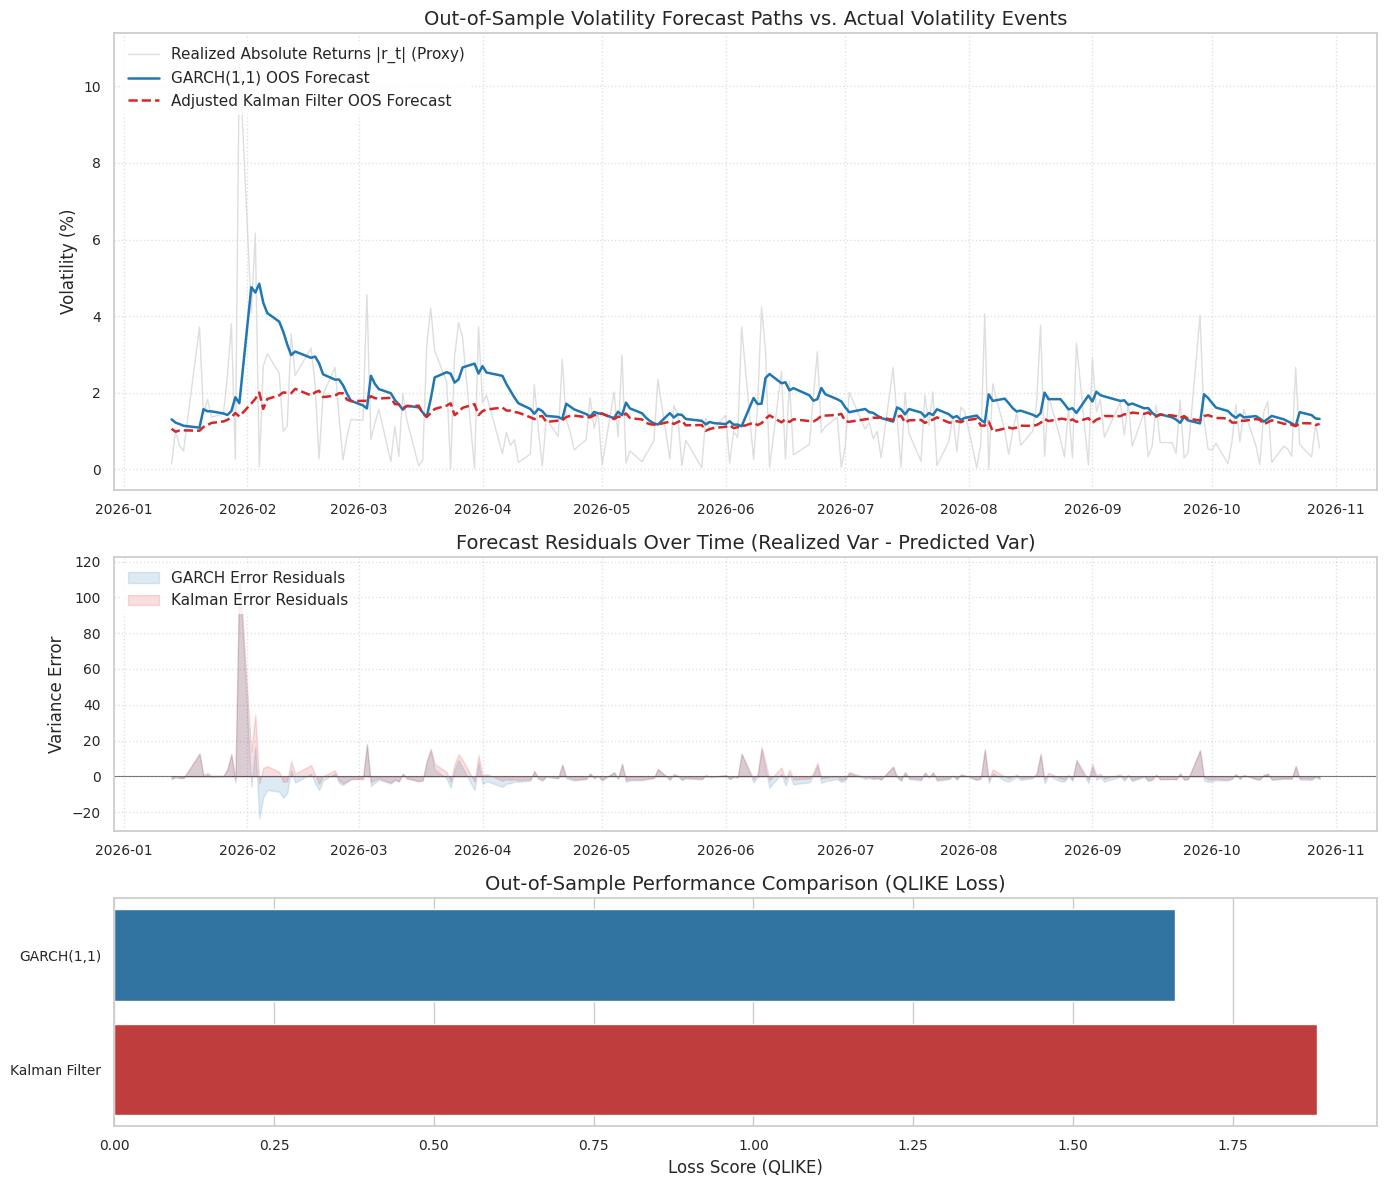

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare dates for the out-of-sample period
oos_dates = df.index[-num_forecasts:]
realized_absolute_returns = np.abs(rets[-num_forecasts:])

# Set sophisticated style for trading desks
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 16
})

fig, axes = plt.subplots(3, 1, figsize=(14, 12), gridspec_kw={'height_ratios': [2, 1.2, 1]})

# --- Plot 1: Volatility Forecast vs Realized Absolute Returns ---
axes[0].plot(oos_dates, realized_absolute_returns, color='lightgray', alpha=0.75, label='Realized Absolute Returns |r_t| (Proxy)', linewidth=1.0)
axes[0].plot(oos_dates, garch_f_arr, color='#1f77b4', label='GARCH(1,1) OOS Forecast', linewidth=1.8)
axes[0].plot(oos_dates, kalman_f_arr, color='#d62728', linestyle='--', label='Adjusted Kalman Filter OOS Forecast', linewidth=1.8)
axes[0].set_title('Out-of-Sample Volatility Forecast Paths vs. Actual Volatility Events')
axes[0].set_ylabel('Volatility (%)')
axes[0].legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- Plot 2: Forecast Errors Tracking ---
garch_errors = realized_var_arr - (garch_f_arr**2)
kalman_errors = realized_var_arr - (kalman_f_arr**2)

axes[1].fill_between(oos_dates, garch_errors, color='#1f77b4', alpha=0.15, label='GARCH Error Residuals')
axes[1].fill_between(oos_dates, kalman_errors, color='#d62728', alpha=0.15, label='Kalman Error Residuals')
axes[1].axhline(0, color='black', linestyle='-', alpha=0.5, linewidth=0.8)
axes[1].set_title('Forecast Residuals Over Time (Realized Var - Predicted Var)')
axes[1].set_ylabel('Variance Error')
axes[1].legend(loc='upper left', frameon=True, facecolor='white', edgecolor='none')
axes[1].grid(True, linestyle=':', alpha=0.6)

# --- Plot 3: Metrics Comparison Scorecard ---
metrics_df = pd.DataFrame({
    'Model': ['GARCH(1,1)', 'Kalman Filter', 'GARCH(1,1)', 'Kalman Filter'],
    'Metric Value': [garch_qlike, kalman_qlike, garch_mse, kalman_mse],
    'Metric Type': ['QLIKE (Lower is Better)', 'QLIKE (Lower is Better)', 'MSE (Lower is Better)', 'MSE (Lower is Better)']
})

sns.barplot(x='Metric Value', y='Model', hue='Model', data=metrics_df[metrics_df['Metric Type'].str.contains('QLIKE')],
            ax=axes[2], palette=['#1f77b4', '#d62728'], legend=False)
axes[2].set_title('Out-of-Sample Performance Comparison (QLIKE Loss)')
axes[2].set_xlabel('Loss Score (QLIKE)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()